# 05. Huấn Luyện Mạng Nơ-ron Sâu PyTorch MLP (`nhanes_mlp.pt`)
Mô hình Deep Learning chủ lực của `PredictionAgent` (**MLP 3 lớp ẩn `128 -> 64 -> 32`** với `BatchNorm1d`, `Dropout(0.2)` và vector đầu vào ghép nối `[z_score, missing_mask]` $2d$ chiều). Artifact xuất ra `/notebook/model/nhanes_mlp.pt`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import train_test_split

from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.models.deep_mlp import MLPRisk
from src.storage.db import engine

spec = DATASETS["nhanes"]
df = load_dataframe(spec, engine)
X, y = df[spec.features].astype(float), df[spec.label].astype(int)
X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_tv, y_tv, test_size=0.125, random_state=42, stratify=y_tv)
X_tr_aug, y_tr_aug = mask_augment(X_tr, y_tr, spec, p=0.4, seed=42)
X_te_masked = mask_augment(X_te, y_te, spec, p=0.4, seed=99)[0].iloc[len(X_te):]

mlp = MLPRisk.train(spec, X_tr_aug, y_tr_aug, X_val, y_val, epochs=60, patience=8)
p_full = mlp.predict_proba(X_te)
p_mask = mlp.predict_proba(X_te_masked)
mlp.metrics = {
    **mlp.metrics,
    "roc_auc": round(float(roc_auc_score(y_te, p_full)), 4),
    "pr_auc": round(float(average_precision_score(y_te, p_full)), 4),
    "brier": round(float(brier_score_loss(y_te, p_full)), 4),
    "masked_roc_auc": round(float(roc_auc_score(y_te, p_mask)), 4),
}
mlp.save()
print("Đã lưu artifact:", mlp.path(spec).relative_to(ROOT))
print("Metrics:", mlp.metrics)

Đã lưu artifact: notebook/model/nhanes_mlp.pt
Metrics: {'epochs_trained': 12, 'best_val_auc': 0.8416, 'roc_auc': 0.825, 'pr_auc': 0.5245, 'brier': 0.1228, 'masked_roc_auc': 0.8039}


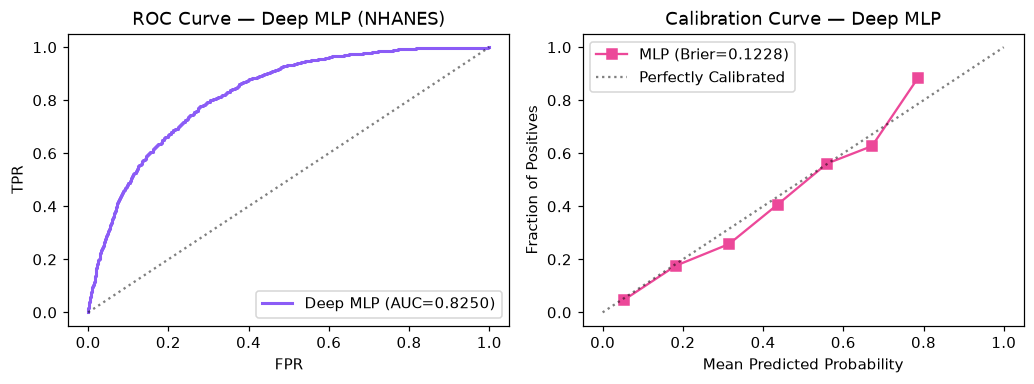

In [2]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

fpr_f, tpr_f, _ = roc_curve(y_te, p_full)
prob_true, prob_pred = calibration_curve(y_te, p_full, n_bins=8)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
axes[0].plot(fpr_f, tpr_f, color="#8b5cf6", lw=2, label=f"Deep MLP (AUC={mlp.metrics['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], "k:", alpha=0.5)
axes[0].set_title("ROC Curve — Deep MLP (NHANES)")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[0].legend()

axes[1].plot(prob_pred, prob_true, "s-", color="#ec4899", label=f"MLP (Brier={mlp.metrics['brier']:.4f})")
axes[1].plot([0, 1], [0, 1], "k:", alpha=0.5, label="Perfectly Calibrated")
axes[1].set_title("Calibration Curve — Deep MLP")
axes[1].set_xlabel("Mean Predicted Probability")
axes[1].set_ylabel("Fraction of Positives")
axes[1].legend()
plt.tight_layout()
